1. Cấu hình và hàm trợ giúp
Giữ bộ đặc trưng từ Bước 03: W=60, rolling median/MAD và sàn Train. Không thêm bộ scaler mới. Mô hình IF mặc định 200 cây, 256 mẫu/cây, seed 42.

In [1]:
"""THI NGHIEM 1 - BUOC 06.1: Isolation Forest baseline A, no labels, no Test access.

Run in a directory containing 03_model_ready_development.csv and
05_val_select_scores.csv, or set DATA_DIR to the correct folder.

Outputs: CSV, PNG, JSON and Markdown in outputs/06_1_if_validation_A.
Strictly fits on Train and scores only Validation SELECT; never reads Test.
"""
from __future__ import annotations

from pathlib import Path
from itertools import combinations
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import IsolationForest
from scipy.stats import spearmanr
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ----- 01. CONFIG (also copied to output JSON) -----
DATA_DIR = Path(".")
if not (DATA_DIR / "03_model_ready_development.csv").is_file():
    DATA_DIR = Path("outputs/03_feature_engineering")
INPUT_FILE = DATA_DIR / "03_model_ready_development.csv"
PREV_SCORES_FILE = Path("05_val_select_scores.csv")
if not PREV_SCORES_FILE.is_file():
    PREV_SCORES_FILE = Path("outputs/05_model_training_A/05_val_select_scores.csv")
OUTPUT_DIR = Path("outputs/06_1_if_validation_A")
FEATURES = ["z_gap", "z_intraday", "z_range", "z_volume"]
BASE_SEED = 42
SEEDS = [7, 19, 42, 73, 101]
BASE_TREES = 200
BASE_SAMPLES = 256
TOP_RATES = [0.01, 0.02, 0.05]
# One-factor-at-a-time variations, not a huge hyperparameter search.
GRID = [
    (100, 256), (200, 256), (400, 256),
    (200, 128), (200, 512),
]
EXPECTED_SHA_FROM_STEP05 = "0f035c54869b7389548ce6ce0b574335ed149e8378b09351eaa8245b840f472a"


def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def top_ids(scores: np.ndarray, n: int) -> set[int]:
    # Stable sorting ensures fully reproducible tie-breaking by row position.
    return set(np.argsort(-scores, kind="stable")[:n].tolist())


def rank_stats(a: np.ndarray, b: np.ndarray, n: int) -> dict:
    aa = top_ids(a, n)
    bb = top_ids(b, n)
    intersection = len(aa & bb)
    union = len(aa | bb)
    return {
        "n_top": n,
        "overlap_count": intersection,
        "overlap_pct_of_top": 100.0 * intersection / n,
        "jaccard": intersection / union if union else np.nan,
    }


def fit_if(x_train: np.ndarray, trees: int, samples: int,
           seed: int, x_val: np.ndarray) -> tuple[IsolationForest, np.ndarray]:
    model = IsolationForest(
        n_estimators=trees,
        max_samples=samples,
        max_features=1.0,
        contamination="auto",
        bootstrap=False,
        random_state=seed,
        n_jobs=1,
    )
    model.fit(x_train)
    scores = -model.score_samples(x_val)
    if not np.isfinite(scores).all():
        raise AssertionError("IF produced NaN or infinite anomaly scores")
    return model, np.asarray(scores, dtype=float)

In [2]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if not INPUT_FILE.is_file():
    raise FileNotFoundError(f"Not found: {INPUT_FILE.resolve()}")

input_sha = sha256_file(INPUT_FILE)
if input_sha != EXPECTED_SHA_FROM_STEP05:
    raise ValueError("Input differs from Step 05. Do not compare different datasets! "
                     f"Got sha256={input_sha}")

df = pd.read_csv(INPUT_FILE, encoding="utf-8-sig")
required = {"ticker", "date", "split", "val_role", *FEATURES}
if not required.issubset(df.columns):
    raise ValueError(f"Missing columns: {required - set(df.columns)}")
if df.duplicated(["ticker", "date"]).any():
    raise ValueError("Duplicate ticker-date")
if not set(df["split"]).issubset({"train", "val"}):
    raise ValueError("Input file unexpectedly includes Test")
# Exclude Val-calibrate explicitly before any numeric analysis.
allowed = df["split"].eq("train") | (df["split"].eq("val") & df["val_role"].eq("select"))
df = df.loc[allowed].copy()
if not df[FEATURES].notna().all().all():
    raise ValueError("Missing model features in Train or Val-select")
if not np.isfinite(df[FEATURES].to_numpy(float)).all():
    raise ValueError("Non-finite model features in Train or Val-select")

train = df[df["split"].eq("train")].sort_values(["date", "ticker"]).reset_index(drop=True)
val = df[df["split"].eq("val") & df["val_role"].eq("select")].sort_values(["date", "ticker"]).reset_index(drop=True)
if len(train) != 10387 or len(val) != 1430:
    raise AssertionError(f"Unexpected counts Train={len(train)}, Val-select={len(val)}")
if pd.to_datetime(train["date"]).max() >= pd.to_datetime(val["date"]).min():
    raise AssertionError("Time overlap between Train and Validation select")
x_train = train[FEATURES].to_numpy(dtype=np.float32)
x_val = val[FEATURES].to_numpy(dtype=np.float32)

print(f"Input verified: {len(train):,} Train; {len(val):,} Val-select; no Test")


Input verified: 10,387 Train; 1,430 Val-select; no Test


In [3]:
# ----- 02. Reproduce Step 05 exactly, without deserializing joblib -----
baseline_model, baseline = fit_if(x_train, BASE_TREES, BASE_SAMPLES, BASE_SEED, x_val)
baseline_df = val[["ticker", "date"] + FEATURES].copy()
baseline_df["score_if"] = baseline
baseline_df["rank_if"] = pd.Series(baseline).rank(ascending=False, method="first").astype(int)
baseline_df["score_percentile"] = pd.Series(baseline).rank(pct=True, method="average")
baseline_df.to_csv(OUTPUT_DIR / "06_1_baseline_val_scores.csv", index=False, encoding="utf-8-sig")

reproduction = {"old_scores_found": PREV_SCORES_FILE.is_file()}
if PREV_SCORES_FILE.is_file():
    prev = pd.read_csv(PREV_SCORES_FILE)
    old = baseline_df[["ticker", "date", "score_if"]].merge(
        prev[["ticker", "date", "score_if"]], on=["ticker", "date"],
        how="outer", validate="one_to_one", suffixes=("_rerun", "_step05"), indicator=True)
    if not old["_merge"].eq("both").all():
        raise AssertionError("Step 05 and Step 06.1 Val-select row identities differ")
    maxdiff = float(np.max(np.abs(old["score_if_rerun"] - old["score_if_step05"])))
    reproduction["max_abs_difference"] = maxdiff
    reproduction["matched_rows"] = len(old)
    if maxdiff > 1e-10:
        raise AssertionError(f"Step 05 baseline not reproduced: max difference {maxdiff}")
    print("Step 05 baseline reproduced. Max absolute score difference:", maxdiff)


Step 05 baseline reproduced. Max absolute score difference: 0.0


In [4]:
# ----- 03. Stability across seed, tree count and max_samples -----
trials = {}
rows_vs_base = []
for trees, samples in GRID:
    for seed in SEEDS:
        if (trees, samples, seed) == (BASE_TREES, BASE_SAMPLES, BASE_SEED):
            scores = baseline
        else:
            _, scores = fit_if(x_train, trees, samples, seed, x_val)
        name = f"trees{trees}_samples{samples}_seed{seed}"
        trials[name] = scores
        row = {"name": name, "n_estimators": trees,
               "max_samples": samples, "seed": seed,
               "spearman_vs_step05_baseline": float(spearmanr(baseline, scores).statistic)}
        for rate in TOP_RATES:
            n = int(np.ceil(len(val) * rate))
            comparison = rank_stats(baseline, scores, n)
            pct = int(rate * 100)
            row[f"top{pct}pct_overlap_pct_vs_baseline"] = comparison["overlap_pct_of_top"]
            row[f"top{pct}pct_jaccard_vs_baseline"] = comparison["jaccard"]
        rows_vs_base.append(row)

comparisons = pd.DataFrame(rows_vs_base)
comparisons.to_csv(OUTPUT_DIR / "06_1_all_runs_vs_baseline.csv", index=False, encoding="utf-8-sig")

pairwise = []
for trees, samples in GRID:
    for seed1, seed2 in combinations(SEEDS, 2):
        a = trials[f"trees{trees}_samples{samples}_seed{seed1}"]
        b = trials[f"trees{trees}_samples{samples}_seed{seed2}"]
        row = {"n_estimators": trees, "max_samples": samples,
               "seed_a": seed1, "seed_b": seed2,
               "spearman": float(spearmanr(a, b).statistic)}
        for rate in TOP_RATES:
            n = int(np.ceil(len(val) * rate))
            stats = rank_stats(a, b, n)
            row[f"top{int(rate * 100)}pct_overlap_pct"] = stats["overlap_pct_of_top"]
            row[f"top{int(rate * 100)}pct_jaccard"] = stats["jaccard"]
        pairwise.append(row)

stability = pd.DataFrame(pairwise)
stability.to_csv(OUTPUT_DIR / "06_1_seed_pairwise.csv", index=False, encoding="utf-8-sig")
summary = stability.groupby(["n_estimators", "max_samples"], as_index=False).agg(
    rho_median=("spearman", "median"),
    rho_min=("spearman", "min"),
    top1_overlap_median_pct=("top1pct_overlap_pct", "median"),
    top1_overlap_min_pct=("top1pct_overlap_pct", "min"),
    top5_overlap_median_pct=("top5pct_overlap_pct", "median"),
    top5_overlap_min_pct=("top5pct_overlap_pct", "min"),
)
summary.to_csv(OUTPUT_DIR / "06_1_stability_summary.csv", index=False, encoding="utf-8-sig")
print("\nSEED STABILITY (pairwise, not accuracy)")
print(summary.round(3).to_string(index=False))



SEED STABILITY (pairwise, not accuracy)
 n_estimators  max_samples  rho_median  rho_min  top1_overlap_median_pct  top1_overlap_min_pct  top5_overlap_median_pct  top5_overlap_min_pct
          100          256       0.980    0.975                   86.667                73.333                   86.111                83.333
          200          128       0.989    0.986                   93.333                86.667                   88.889                84.722
          200          256       0.990    0.987                   86.667                80.000                   91.667                87.500
          200          512       0.987    0.982                   86.667                80.000                   91.667                88.889
          400          256       0.994    0.992                   93.333                86.667                   95.139                91.667


In [5]:
# ----- 04. Ablation: diagnostic for dependence on one feature -----
ablation_rows = []
for omitted in FEATURES:
    cols = [c for c in FEATURES if c != omitted]
    _, s = fit_if(train[cols].to_numpy(np.float32), BASE_TREES,
                  BASE_SAMPLES, BASE_SEED, val[cols].to_numpy(np.float32))
    row = {"omitted_feature": omitted, "n_features": len(cols),
           "spearman_vs_full_if": float(spearmanr(baseline, s).statistic)}
    for rate in TOP_RATES:
        n = int(np.ceil(len(val) * rate))
        stat = rank_stats(baseline, s, n)
        row[f"top{int(rate*100)}pct_overlap_count"] = stat["overlap_count"]
        row[f"top{int(rate*100)}pct_overlap_pct"] = stat["overlap_pct_of_top"]
    ablation_rows.append(row)
ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(OUTPUT_DIR / "06_1_feature_ablation.csv", index=False, encoding="utf-8-sig")
print("\nFEATURE ABLATION (rank comparison, not ground-truth importance)")
print(ablation.round(3).to_string(index=False))



FEATURE ABLATION (rank comparison, not ground-truth importance)
omitted_feature  n_features  spearman_vs_full_if  top1pct_overlap_count  top1pct_overlap_pct  top2pct_overlap_count  top2pct_overlap_pct  top5pct_overlap_count  top5pct_overlap_pct
          z_gap           3                0.899                      9               60.000                     20               68.966                     54               75.000
     z_intraday           3                0.913                      9               60.000                     19               65.517                     53               73.611
        z_range           3                0.923                     11               73.333                     19               65.517                     54               75.000
       z_volume           3                0.916                     12               80.000                     25               86.207                     59               81.944


In [11]:
# ----- 05. Inspect high-score sessions and concentration -----
top_blocks = []
date_rows = []
ticker_rows = []
for rate in TOP_RATES:
    n = int(np.ceil(len(val) * rate))
    ids = np.argsort(-baseline, kind="stable")[:n]
    top = baseline_df.iloc[ids].copy()
    top.insert(0, "top_rate", rate)
    top.insert(1, "top_n", n)
    top_blocks.append(top)
    for date, count in top.groupby("date").size().items():
        date_rows.append({"top_rate": rate, "date": date, "n_tickers": int(count)})
    for ticker, count in top.groupby("ticker").size().items():
        ticker_rows.append({"top_rate": rate, "ticker": ticker, "n_rows": int(count)})

high_scores = pd.concat(top_blocks, ignore_index=True)
high_scores.to_csv(OUTPUT_DIR / "06_1_top_scored_sessions.csv", index=False, encoding="utf-8-sig")
date_conc = pd.DataFrame(date_rows).sort_values(["top_rate", "n_tickers", "date"], ascending=[True, False, True])
date_conc.to_csv(OUTPUT_DIR / "06_1_concentration_by_date.csv", index=False, encoding="utf-8-sig")
ticker_conc = pd.DataFrame(ticker_rows).sort_values(["top_rate", "n_rows", "ticker"], ascending=[True, False, True])
ticker_conc.to_csv(OUTPUT_DIR / "06_1_concentration_by_ticker.csv", index=False, encoding="utf-8-sig")

# ----- 05b. Calendar concentration (descriptive only) -----
month_rows = []
val_month_counts = val.assign(month=val["date"].str.slice(0, 7)).groupby("month").size()
for rate in TOP_RATES:
    t = high_scores.loc[high_scores["top_rate"].eq(rate)].copy()
    top_month_counts = t.assign(month=t["date"].str.slice(0, 7)).groupby("month").size()
    for month, count_val in val_month_counts.items():
        count_top = int(top_month_counts.get(month, 0))
        month_rows.append({"top_rate": rate, "month": month,
                           "val_select_rows": int(count_val),
                           "top_n": int(len(t)),
                           "top_rows_in_month": count_top,
                           "month_share_of_val_pct": 100 * count_val / len(val),
                           "month_share_of_top_pct": 100 * count_top / len(t),
                           "top_rate_within_month_pct": 100 * count_top / count_val})
month_conc = pd.DataFrame(month_rows)
month_conc.to_csv(OUTPUT_DIR / "06_1_concentration_by_month.csv", index=False, encoding="utf-8-sig")


In [12]:
# ----- 06. Gap diagnostics, *no row removal* -----
val_gap = baseline_df.loc[baseline_df["z_gap"].abs() > 30].copy()
val_gap = val_gap.sort_values("score_if", ascending=False)
val_gap.to_csv(OUTPUT_DIR / "06_1_gap_extreme_val_review.csv", index=False, encoding="utf-8-sig")
x_train_gap = train.loc[train["z_gap"].abs() > 30].copy()
x_train_gap["score_if_on_train"] = -baseline_model.score_samples(
    x_train_gap[FEATURES].to_numpy(np.float32))
x_train_gap[["ticker", "date", "z_gap", "score_if_on_train"]].to_csv(
    OUTPUT_DIR / "06_1_gap_extreme_train_review.csv", index=False, encoding="utf-8-sig")

correlations = []
for f in FEATURES:
    correlations.append({"feature": f, "spearman_abs_feature_vs_if_score_on_val":
                         float(spearmanr(val[f].abs(), baseline).statistic)})
pd.DataFrame(correlations).to_csv(OUTPUT_DIR / "06_1_abs_feature_score_associations.csv",
                                   index=False, encoding="utf-8-sig")


In [13]:
# ----- 07. One plot with meaningful readout -----
plt.figure(figsize=(9.5, 4.7))
x = np.arange(len(summary))
plt.bar(x - 0.16, summary["top1_overlap_median_pct"], width=0.32, label="Top 1%")
plt.bar(x + 0.16, summary["top5_overlap_median_pct"], width=0.32, label="Top 5%")
plt.xticks(x, [f"trees={int(t)}\nsamples={int(s)}" for t,s in zip(summary.n_estimators, summary.max_samples)], rotation=0)
plt.ylabel("Median pairwise overlap (%)")
plt.ylim(0, 105)
plt.title("IF baseline A: consistency of top-ranked sessions across seeds")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_1_seed_stability.png", dpi=180)
plt.close()


In [16]:

%pip install tabulate

  Obtaining dependency information for tabulate from https://files.pythonhosted.org/packages/99/55/db07de81b5c630da5cbf5c7df646580ca26dfaefa593667fc6f2fe016d2e/tabulate-0.10.0-py3-none-any.whl.metadata
     ---------------------------------------- 0.0/40.8 kB ? eta -:--:--
     ------------------- ------------------ 20.5/40.8 kB 217.9 kB/s eta 0:00:01
     ---------------------------- --------- 30.7/40.8 kB 262.6 kB/s eta 0:00:01
     -------------------------------------- 40.8/40.8 kB 277.7 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:

import tabulate

print("Tabulate version:", tabulate.__version__)
print("Đã cài đặt thành công!")

Tabulate version: 0.10.0
Đã cài đặt thành công!


In [18]:
# ----- 08. Results and cautious recommendation -----
ref = summary.loc[(summary.n_estimators == 200) & (summary.max_samples == 256)].iloc[0]
metrics = {
    "step": "06_1_if_baseline_A_validation",
    "input_sha256": input_sha,
    "train_n": int(len(train)), "val_select_n": int(len(val)),
    "baseline": {"trees": BASE_TREES, "max_samples": BASE_SAMPLES,
                 "seed": BASE_SEED, "contamination": "auto", "scoring": "-score_samples"},
    "all_test_data_unused": True,
    "all_validation_calibrate_unused": True,
    "seeds": SEEDS,
    "grid": [{"trees": t, "max_samples": s} for t,s in GRID],
    "top_n": {str(r): int(np.ceil(len(val)*r)) for r in TOP_RATES},
    "reproduction": reproduction,
    "baseline_seed_pairwise": {
        "spearman_median": float(ref.rho_median),
        "spearman_min": float(ref.rho_min),
        "top1_overlap_pct_median": float(ref.top1_overlap_median_pct),
        "top1_overlap_pct_min": float(ref.top1_overlap_min_pct),
        "top5_overlap_pct_median": float(ref.top5_overlap_median_pct),
        "top5_overlap_pct_min": float(ref.top5_overlap_min_pct),
    },
    "gap_extreme_count_train": len(x_train_gap),
    "gap_extreme_count_val_select": len(val_gap),
    "software": {"python": platform.python_version(),
                 "numpy": np.__version__, "pandas": pd.__version__,
                 "sklearn": sklearn.__version__},
    "limitations": [
        "No ground-truth labels; metrics are stability/consistency only",
        "Top-K comparison is an analyst review diagnostic, not a calibrated alert threshold",
        "Only W=60 fixed feature input is used, no W/floor tuning",
        "Ablation refits with three features; rank change is not causal feature importance",
        "Train contains possible anomalies; no sessions deleted",
        "Previously used Test period must be audited before calling final Test independent",
    ],
}
(OUTPUT_DIR / "06_1_if_config_metrics.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")

focus = date_conc.loc[date_conc["top_rate"].eq(0.05)].head(5)
apr = month_conc.loc[(month_conc["top_rate"].eq(0.05)) & (month_conc["month"].eq("2025-04"))]
if len(apr):
    apr = apr.iloc[0]
else:
    raise AssertionError("April 2025 absent from Validation select")
report = f"""# Thí nghiệm 1 — Bước 06.1: Isolation Forest baseline A

## Phạm vi
- Train: **{len(train):,}**; Validation chọn cấu hình: **{len(val):,}**; **loại Val calibrate trước khi phân tích và không sử dụng Test**.
- Bốn đặc trưng `z_gap, z_intraday, z_range, z_volume`, W=60, giữ nguyên dữ liệu và chuẩn hóa Bước 03.
- IF baseline **200 cây × 256 mẫu/cây, seed 42**, điểm cao = khác thường hơn (`-score_samples`).
- Không gắn nhãn thật và không đặt ngưỡng cảnh báo; top 1%, 2%, 5% chỉ là tập cố định để so thứ hạng.

## Kiểm tra tái lập Bước 05
{json.dumps(reproduction, ensure_ascii=False)}

## Ổn định khi đổi seed ở cấu hình baseline (5 seed, 10 cặp)
- Spearman: trung vị **{ref.rho_median:.4f}**, thấp nhất **{ref.rho_min:.4f}**.
- Top 1%: trung vị trùng **{ref.top1_overlap_median_pct:.1f}%**, thấp nhất **{ref.top1_overlap_min_pct:.1f}%**.
- Top 5%: trung vị trùng **{ref.top5_overlap_median_pct:.1f}%**, thấp nhất **{ref.top5_overlap_min_pct:.1f}%**.
- Không có tiêu chuẩn thống kê chung để tuyên bố bao nhiêu % trùng là 'đạt'. Xem cả bảng chi tiết và theo từng ngày/mã.

## Các quan sát cần rà
- Phiên |z_gap|>30 trên Train: **{len(x_train_gap)}**, Val-select: **{len(val_gap)}**. Đều **được giữ nguyên**, không dùng để lọc Train.
- Bảng 06_1_feature_ablation.csv cho biết *mức thay đổi thứ hạng* khi bỏ từng đặc trưng, không phải độ chính xác hay tầm quan trọng nhân quả.
- Các ngày có nhiều mã nằm trong top 5% theo IF baseline (chỉ là mô tả):
{focus.to_markdown(index=False)}
- Tháng 04/2025 chỉ có **{apr.val_select_rows} / {len(val)}** phiên Val-select (**{apr.month_share_of_val_pct:.1f}%**), nhưng có **{apr.top_rows_in_month} / {apr.top_n}** phiên top 5% (**{apr.month_share_of_top_pct:.1f}%**). Đây là **tập trung theo thời gian** cần phân tích, không chứng minh lỗi hoặc một nguyên nhân thị trường cụ thể.

## Cần làm gì tiếp?
1. Đọc các bảng về seed, tham số và ablation để hiểu phương án A có ổn định hay không.
2. Kiểm tra những phiên/nhóm ngày có điểm cao; không tự suy ra sự kiện, thao túng hoặc chất lượng dự báo.
3. Kiểm tra phản ứng với biến đổi OHLCV hợp lệ ở Bước 06.4; so IF với AE/LOF ở Bước 06.5.
4. Chỉ sử dụng Val calibrate để lấy ngưỡng ở Bước 07 sau khi chốt cấu hình, không dùng Test để sửa.
"""
(OUTPUT_DIR / "06_1_if_report.md").write_text(report, encoding="utf-8")
print("\nBASELINE seed reproducibility and summary saved:", OUTPUT_DIR.resolve())
print("TOP 5% concentrated days:")
print(focus.to_string(index=False))
print(f"April 2025: {apr.val_select_rows}/{len(val)} Val-select rows but "
      f"{apr.top_rows_in_month}/{apr.top_n} top-5% rows")
print("NO decision that IF is correct or superior has been made.")



BASELINE seed reproducibility and summary saved: D:\LUẬN VĂN\stock-news-anomaly-project\Stocks\notebooks\outputs\06_1_if_validation_A
TOP 5% concentrated days:
 top_rate       date  n_tickers
     0.05 2025-04-04         11
     0.05 2025-04-09          8
     0.05 2025-04-11          7
     0.05 2025-04-03          6
     0.05 2025-04-08          6
April 2025: 247/1430 Val-select rows but 57/72 top-5% rows
NO decision that IF is correct or superior has been made.


Độ ổn định theo cấu hình:


,n_estimators,max_samples,rho_median,rho_min,top1_overlap_median_pct,top1_overlap_min_pct,top5_overlap_median_pct,top5_overlap_min_pct
0,100,256,0.980,0.975,86.667,73.333,86.111,83.333
1,200,128,0.989,0.986,93.333,86.667,88.889,84.722
2,200,256,0.990,0.987,86.667,80.000,91.667,87.500
3,200,512,0.987,0.982,86.667,80.000,91.667,88.889
4,400,256,0.994,0.992,93.333,86.667,95.139,91.667



Bỏ từng đặc trưng:


,omitted_feature,n_features,spearman_vs_full_if,top1pct_overlap_count,top1pct_overlap_pct,top2pct_overlap_count,top2pct_overlap_pct,top5pct_overlap_count,top5pct_overlap_pct
0,z_gap,3,0.899,9,60.000,20,68.966,54,75.000
1,z_intraday,3,0.913,9,60.000,19,65.517,53,73.611
2,z_range,3,0.923,11,73.333,19,65.517,54,75.000
3,z_volume,3,0.916,12,80.000,25,86.207,59,81.944



Các phiên có điểm cao nhất (top 1%):


,top_rate,top_n,ticker,date,z_gap,z_intraday,z_range,z_volume,score_if,rank_if,score_percentile
0,0.01,15,VNM,2025-04-04,-19.752695,9.791715,12.880872,2.988267,0.777290,1,1.000000
1,0.01,15,VHC,2025-04-11,10.222388,-7.530637,10.582142,2.719045,0.761849,2,0.999301
2,0.01,15,VNM,2025-04-03,-7.683717,-5.550915,7.604793,4.311202,0.754996,3,0.998601
3,0.01,15,SAB,2025-04-09,-9.104930,7.306425,10.260788,2.073279,0.743487,4,0.997902
4,0.01,15,PNJ,2025-04-03,-9.936329,-4.501093,6.220912,3.127954,0.736792,5,0.997203
5,0.01,15,DHG,2025-04-04,-28.655081,5.109455,6.238013,2.400660,0.734420,6,0.996503
6,0.01,15,VNM,2025-04-08,-13.849199,-4.134904,5.282624,3.637231,0.733605,7,0.995804
7,0.01,15,SBT,2025-04-15,-34.371885,9.043613,5.165512,1.200933,0.732842,8,0.995105
8,0.01,15,ANV,2025-05-06,-13.164763,5.345815,7.417118,1.974895,0.730836,9,0.994406
9,0.01,15,VNM,2025-04-09,-25.361898,1.823746,9.953311,2.854125,0.725874,10,0.993706



Tập trung theo tháng:


,top_rate,month,val_select_rows,top_n,top_rows_in_month,month_share_of_val_pct,month_share_of_top_pct,top_rate_within_month_pct
12,0.05,2025-04,247,72,57,17.27,79.17,23.08
13,0.05,2025-05,260,72,1,18.18,1.39,0.38
14,0.05,2025-06,273,72,2,19.09,2.78,0.73
15,0.05,2025-07,299,72,8,20.91,11.11,2.68
16,0.05,2025-08,273,72,4,19.09,5.56,1.47
17,0.05,2025-09,78,72,0,5.45,0.00,0.00


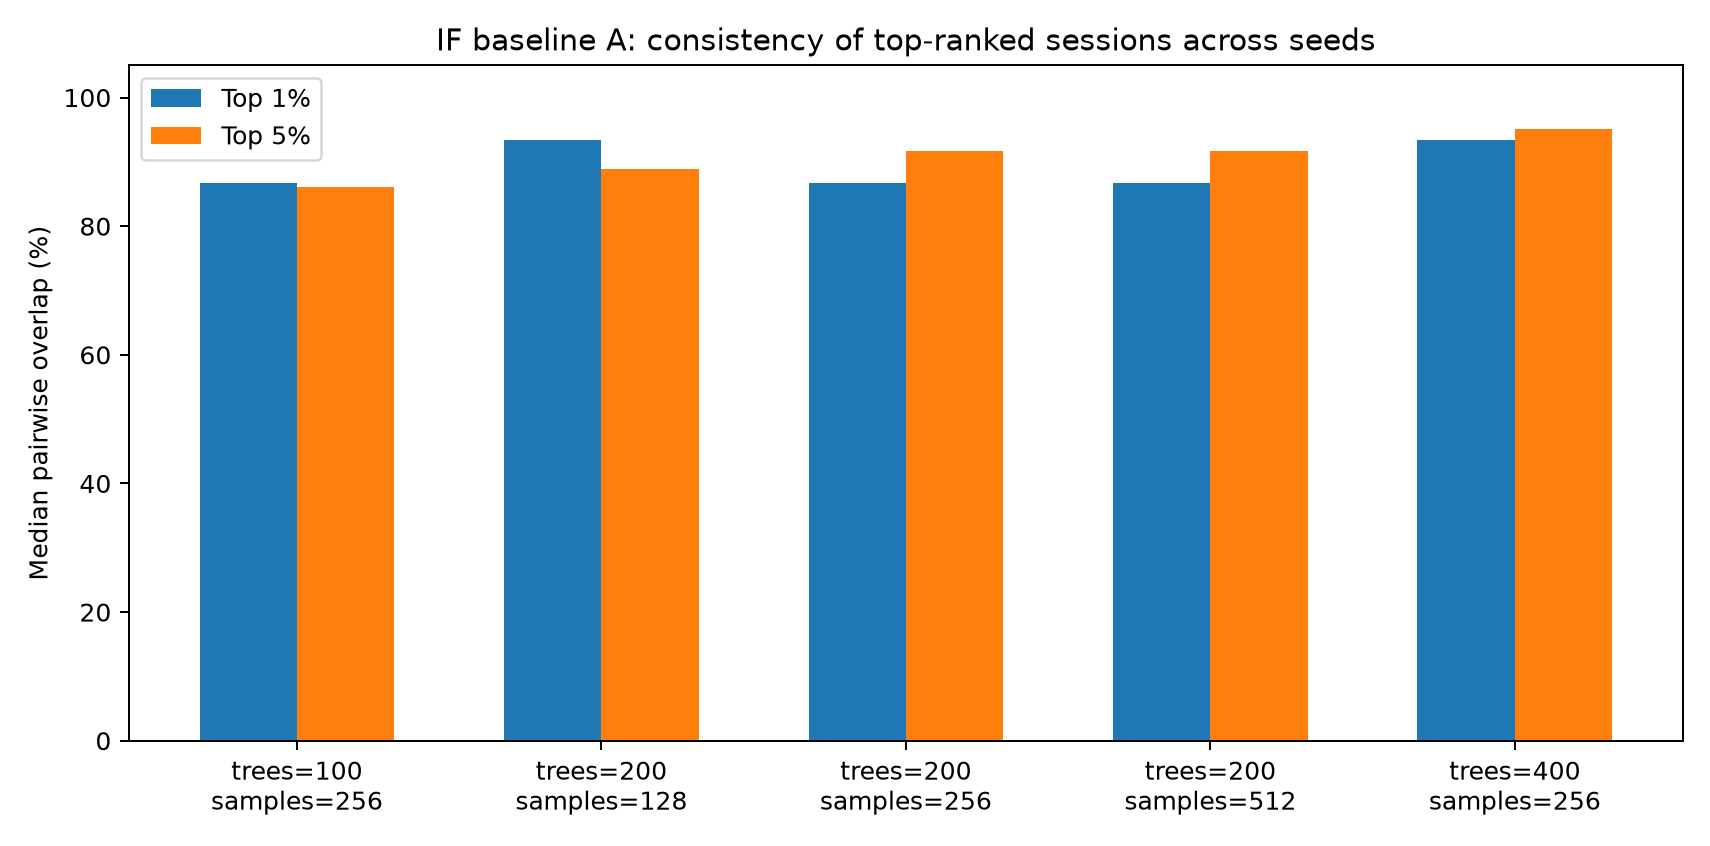

In [19]:
from IPython.display import display, Image
print("Độ ổn định theo cấu hình:")
display(pd.read_csv(OUTPUT_DIR / "06_1_stability_summary.csv").round(3))
print("\nBỏ từng đặc trưng:")
display(pd.read_csv(OUTPUT_DIR / "06_1_feature_ablation.csv").round(3))
print("\nCác phiên có điểm cao nhất (top 1%):")
display(pd.read_csv(OUTPUT_DIR / "06_1_top_scored_sessions.csv").query("top_rate == 0.01").head(15))
print("\nTập trung theo tháng:")
display(pd.read_csv(OUTPUT_DIR / "06_1_concentration_by_month.csv").query("top_rate == 0.05").round(2))
display(Image(filename=str(OUTPUT_DIR / "06_1_seed_stability.png")))